# Лабораторна робота № 4. 
**Тема:** Використання лінійних моделей в задачах інтелектуального аналізу даних.

## Завдання №1 
Визначіть цільову змінну, яка залежить від певних ознак, описаних в обраному датасеті. Із отриманим датасетом виконати усі операції розв’язання задачі лінійної регресії

In [17]:
%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [18]:
h_price = pd.read_csv('Housing_Price_Data.csv')

In [19]:
h_price.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning
0,13300000,7420,4,2,3,yes,no,no,no,yes
1,12250000,8960,4,4,4,yes,no,no,no,yes
2,12250000,9960,3,2,2,yes,no,yes,no,no
3,12215000,7500,4,2,2,yes,no,yes,no,yes
4,11410000,7420,4,1,2,yes,yes,yes,no,yes


In [20]:
h_price.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning'],
      dtype='object')

In [21]:
# Вибираємо текстові колонки і кодуємо їх
binary_cols = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
]
for col in binary_cols:
    if col in h_price.columns:
        h_price[col] = h_price[col].map({'yes': 1, 'no': 0})


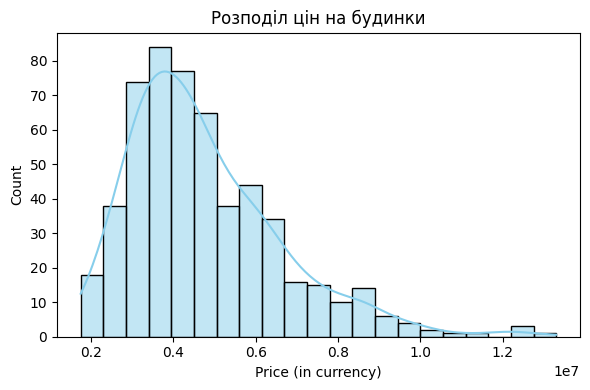

In [22]:
plt.figure(figsize=(6,4))
sns.histplot(h_price['price'], kde=True, color='skyblue')
plt.xlabel('Price (in currency)')
plt.ylabel('Count')
plt.title('Розподіл цін на будинки')
plt.tight_layout()
plt.show()

In [23]:
# Вибираємо числові ознаки для передбачення ціни
feature_names = [
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'hotwaterheating',
    'airconditioning',   
]
x = h_price[feature_names].values
y = h_price['price'].values


In [25]:
# Створюємо екземпляр класу LinearRegression і навчаємо модель
linear_regression = LinearRegression()
model = linear_regression.fit(x, y)
print("Модель успішно навчено!")

Модель успішно навчено!


In [27]:
# Аналіз вагових коефіцієнтів 
feature_weight_df = pd.DataFrame(list(zip(feature_names, model.coef_)))
feature_weight_df.columns = ['Feature', 'Weight']
print(feature_weight_df)
print(f'Вільний коефіцієнт (intercept): {model.intercept_:.2f}')

           Feature        Weight
0             area  3.406832e+02
1         bedrooms  1.881220e+05
2        bathrooms  1.111949e+06
3          stories  3.930541e+05
4  hotwaterheating  9.222479e+05
5  airconditioning  1.034156e+06
Вільний коефіцієнт (intercept): -54354.28


In [28]:
# Перебачення та порівняння з реальними даними
predicted = model.predict(x)
print('Перші 10 передбачень:', predicted[:10])

Перші 10 передбачень: [ 7663218.84278833 10804822.47742976  6913221.75560499  7297419.364684
  6158215.9921393   7828191.92814565  9563414.15732731 10527277.43589791
  6389880.53993686  7299210.07322202]


In [30]:
# Таблиця порівняння передбачень та реальних цін
predictions_ground_truth_df = pd.DataFrame(
    {'Prediction': predicted, 'Ground truth': h_price['price']}
)

print(predictions_ground_truth_df.head(10))

     Prediction  Ground truth
0  7.663219e+06      13300000
1  1.080482e+07      12250000
2  6.913222e+06      12250000
3  7.297419e+06      12215000
4  6.158216e+06      11410000
5  7.828192e+06      10850000
6  9.563414e+06      10150000
7  1.052728e+07      10150000
8  6.389881e+06       9870000
9  7.299210e+06       9800000


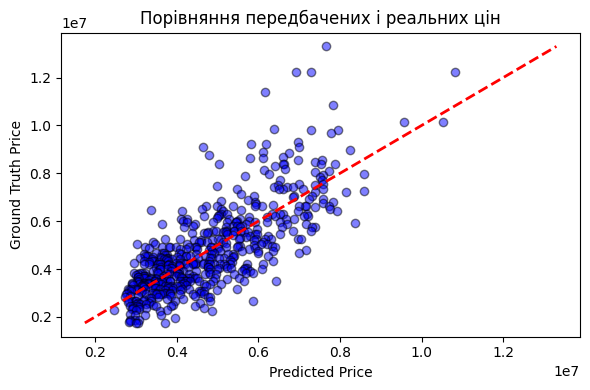

In [31]:
# Графічне порівняння
plt.figure(figsize=(6, 4))
plt.scatter(
    predicted, h_price['price'], alpha=0.5, color='blue', edgecolor='k'
)
plt.xlabel('Predicted Price')
plt.ylabel('Ground Truth Price')
# Лінія ідеального передбачення (від мінімальної до максимальної ціни)
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color='red',
    linestyle='--',
    linewidth=2,
)
plt.title('Порівняння передбачених і реальних цін')
plt.tight_layout()
plt.show()

## Завдання №2
Для отриманого датасету потрібно визначити два основних типи класу, за якими буде відбуватись класифікація ознак об’єкта. З отриманим датасетом виконати усі операції розв’язання задачі класифікації

In [34]:
df = pd.read_csv('diabetes.xls')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


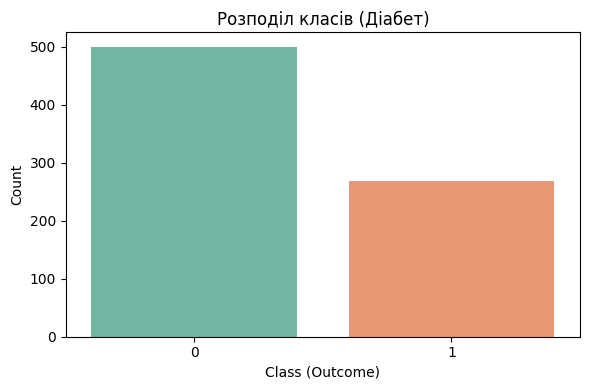

In [37]:
# Аналіз та візуалізація розподілу класів
plt.figure(figsize=(6, 4))
sns.countplot(
    x='Outcome', data=df, hue='Outcome', palette='Set2', legend=False
)
plt.xlabel('Class (Outcome)')
plt.ylabel('Count')
plt.title('Розподіл класів (Діабет)')
plt.tight_layout()
plt.show()fro

In [38]:
from sklearn.linear_model import LogisticRegression

In [40]:
# Навчання моделі логістичної регресії
x = df.drop(columns=['Outcome']).values
y = df['Outcome'].values

logistic_regression = LogisticRegression(max_iter=1000)
model = logistic_regression.fit(x,y)
print("Модель логістичної регресії успішно навчено!")
print('Коефіціети моделі (coef_:)', model.coef_)

Модель логістичної регресії успішно навчено!
Коефіціети моделі (coef_:) [[ 1.22501395e-01  3.51105502e-02 -1.32989578e-02  7.80589400e-04
  -1.17380633e-03  8.96527697e-02  8.67802716e-01  1.49845953e-02]]


In [41]:
# Передбачення класів та ймовірностей
prediction = model.predict(x)
print('Перші 10 передбачених класів:', prediction[:10])

Перші 10 передбачених класів: [1 0 1 0 1 0 0 1 1 0]


In [43]:
# Перевірка впевненості моделі (ймовірності для кожного класу)
prediction_proba = model.predict_proba(x)
print('Перші 10 передбачень ймовірностей (клас 0 і клас 1):\n', prediction_proba[:10])

Перші 10 передбачень ймовірностей (клас 0 і клас 1):
 [[0.28057044 0.71942956]
 [0.95071141 0.04928859]
 [0.20743085 0.79256915]
 [0.95726817 0.04273183]
 [0.11035107 0.88964893]
 [0.85131115 0.14868885]
 [0.93202967 0.06797033]
 [0.35135191 0.64864809]
 [0.28310676 0.71689324]
 [0.96312248 0.03687752]]


In [45]:
# Оцінка точності моделі
print('Accuracy: {:.4f}'.format(model.score(x, y)))

Accuracy: 0.7812
